# Exploratory analysis

Questions to answer before any modelling:

- How imbalanced is the data, and what does that mean for evaluation?
- Are there duplicates or missing values?
- Do the amount and the time of day carry signal, and in what shape?
- Which anonymised components separate fraud from legitimate transactions?

The notebook reads `data/raw/creditcard.csv` when it exists and falls back to the synthetic sample otherwise. The written conclusions refer to the real dataset.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from fraudguard.config import load_config
from fraudguard.data_ingestion import (
    AMOUNT_COLUMN,
    PCA_COLUMNS,
    SECONDS_PER_DAY,
    SECONDS_PER_HOUR,
    TARGET_COLUMN,
    TIME_COLUMN,
    load_raw_transactions,
)
from fraudguard.data_validation import validate_transactions
from fraudguard.plotting import BLUE, GRID, INK_SECONDARY, NEUTRAL, ORANGE, SURFACE

plt.rcParams.update(
    {
        'figure.facecolor': SURFACE,
        'axes.facecolor': SURFACE,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.grid': True,
        'axes.axisbelow': True,
        'axes.titlelocation': 'left',
        'grid.color': GRID,
        'axes.labelcolor': INK_SECONDARY,
        'legend.frameon': False,
    }
)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
config = load_config(ROOT / 'config' / 'config.yaml')

In [2]:
raw_path = ROOT / config.data.raw_path
data_path = raw_path if raw_path.is_file() else ROOT / config.data.sample_path
frame = load_raw_transactions(data_path)
is_fraud = frame[TARGET_COLUMN] == 1
print(f'{data_path.name}: {len(frame):,} rows, {frame.shape[1]} columns')

creditcard.csv: 284,807 rows, 31 columns


## Class balance

In [3]:
counts = frame[TARGET_COLUMN].value_counts().rename(index={0: 'legitimate', 1: 'fraud'})
pd.DataFrame({'transactions': counts, 'share': (counts / len(frame)).map('{:.3%}'.format)})

,transactions,share
is_fraud,,
legitimate,284315,99.827%
fraud,492,0.173%


Fraud is 0.17% of transactions. A rule that labels everything legitimate is 99.83% accurate and catches no fraud, so accuracy says nothing useful here. The project uses PR-AUC to compare models and an explicit cost model to choose the decision threshold.

With 492 fraud cases in total, a 20% test split holds fewer than 100. Every metric on it carries wide uncertainty, which is why the evaluation report gives bootstrap intervals.

## Data quality

In [4]:
report = validate_transactions(frame, config.validation)
pd.DataFrame(report.to_dict()['checks'])

,name,status,message
0,schema,passed,All 31 required columns present
1,missing_values,passed,No missing input values
2,duplicates,warning,"1,081 duplicate rows (0.38%) will be dropped b..."
3,value_ranges,passed,All values within valid ranges
4,class_balance,passed,492 fraud rows (0.173%)


In [5]:
duplicates = frame[frame.duplicated()]
duplicate_fraud = int(duplicates[TARGET_COLUMN].sum())
print(f'{len(duplicates):,} duplicate rows, {duplicate_fraud} of them labelled fraud')

1,081 duplicate rows, 19 of them labelled fraud


There are no missing values, but 1,081 rows are exact copies of another row, 19 of them fraud. If a copy sat in the training split and its twin in the test split, the model would be scored on rows it has already seen. The pipeline drops duplicates before splitting and checks that no input vector appears in two splits.

## Amount

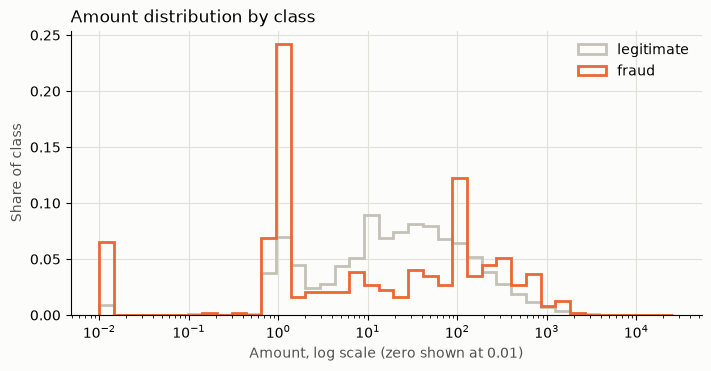

In [6]:
bins = np.logspace(-2, np.log10(frame[AMOUNT_COLUMN].max() + 1), 40)
fig, ax = plt.subplots(figsize=(7, 3.6), layout='constrained')
for mask, colour, label in ((~is_fraud, NEUTRAL, 'legitimate'), (is_fraud, ORANGE, 'fraud')):
    amounts = frame.loc[mask, AMOUNT_COLUMN].clip(lower=0.01)
    weights = np.full(len(amounts), 1 / len(amounts))
    ax.hist(
        amounts, bins=bins, weights=weights, histtype='step', linewidth=2, color=colour, label=label
    )
ax.set(xscale='log', xlabel='Amount, log scale (zero shown at 0.01)', ylabel='Share of class')
ax.set_title('Amount distribution by class')
ax.legend()
plt.show()

In [7]:
edges = [0, *config.features.amount_bucket_edges, np.inf]
buckets = pd.cut(frame[AMOUNT_COLUMN], edges, right=False)
by_bucket = frame.groupby(buckets, observed=True)[TARGET_COLUMN].agg(
    transactions='size', fraud_rate='mean'
)
by_bucket.assign(fraud_rate=by_bucket['fraud_rate'].map('{:.3%}'.format))

,transactions,fraud_rate
amount,,
"[0.0, 1.0)",16804,0.405%
"[1.0, 10.0)",80510,0.225%
"[10.0, 50.0)",92390,0.061%
"[50.0, 100.0)",37718,0.151%
"[100.0, 500.0)",47893,0.198%
"[500.0, 1000.0)",6423,0.405%
"[1000.0, inf)",3069,0.293%


Amounts span five orders of magnitude, so the model gets `ln(1 + amount)` instead of the raw value. Fraud is over-represented below 1, the range used to test stolen card numbers, and again above 500. The bucket feature lets the linear baseline treat those ranges separately from the overall trend.

## Time of day

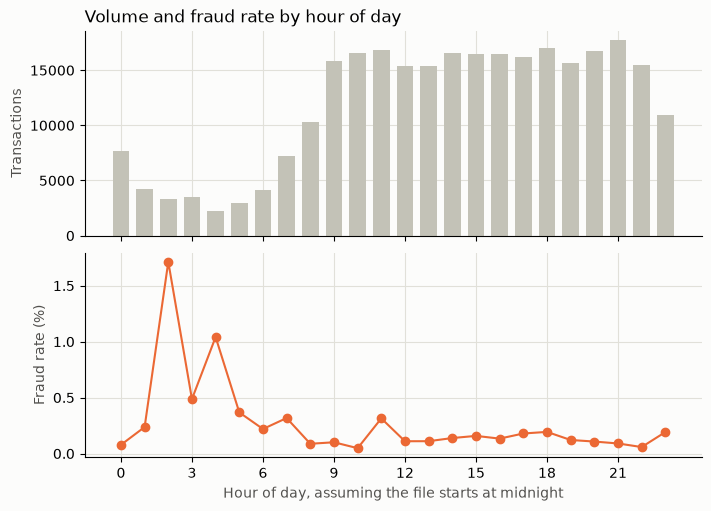

In [8]:
hour = (frame[TIME_COLUMN] % SECONDS_PER_DAY) // SECONDS_PER_HOUR
by_hour = frame.groupby(hour)[TARGET_COLUMN].agg(transactions='size', fraud_rate='mean')
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 5), sharex=True, layout='constrained')
top.bar(by_hour.index, by_hour['transactions'], color=NEUTRAL, width=0.7)
top.set(ylabel='Transactions')
top.set_title('Volume and fraud rate by hour of day')
bottom.plot(by_hour.index, by_hour['fraud_rate'] * 100, color=ORANGE, marker='o')
bottom.set(xlabel='Hour of day, assuming the file starts at midnight', ylabel='Fraud rate (%)')
bottom.set_xticks(range(0, 24, 3))
plt.show()

`Time` counts seconds from the first transaction, so on its own it only describes the two days of collection. Volume drops sharply in hours 1 to 6, which fits the file starting at midnight. In those hours the fraud rate is several times the daytime rate. The model keeps the hour of day as a sine and cosine pair, so that 23:00 and 00:00 stay close, and drops the raw counter.

## Anonymised components

In [9]:
correlation = frame[PCA_COLUMNS].corr().abs().to_numpy(copy=True)
np.fill_diagonal(correlation, 0)
print(f'Largest absolute correlation between two components: {correlation.max():.3f}')

Largest absolute correlation between two components: 0.000


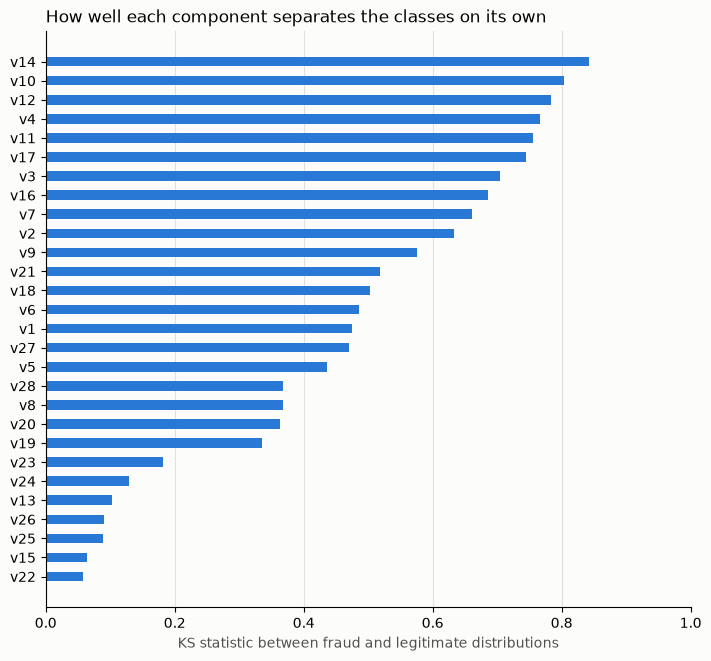

In [10]:
separation = pd.Series(
    {
        name: stats.ks_2samp(frame.loc[is_fraud, name], frame.loc[~is_fraud, name]).statistic
        for name in PCA_COLUMNS
    }
).sort_values()
fig, ax = plt.subplots(figsize=(7, 6.5), layout='constrained')
ax.barh(separation.index, separation.to_numpy(), height=0.5, color=BLUE)
ax.set(xlabel='KS statistic between fraud and legitimate distributions', xlim=(0, 1))
ax.set_title('How well each component separates the classes on its own')
ax.grid(visible=False, axis='y')
plt.show()

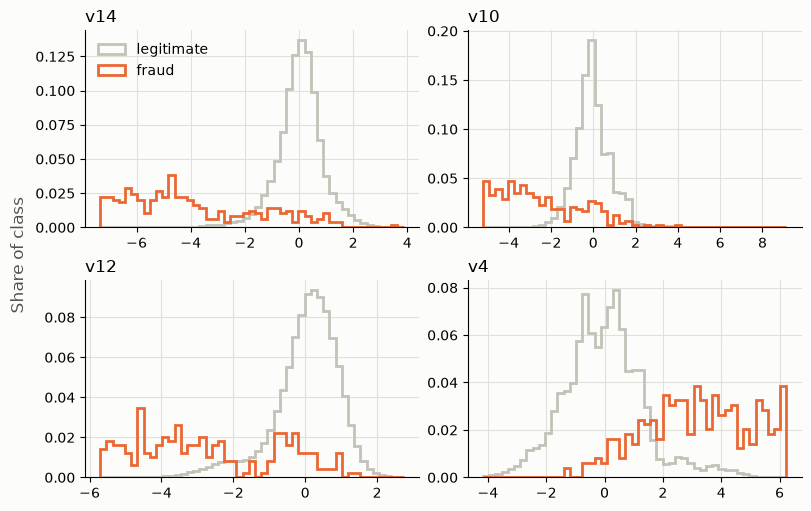

In [11]:
top_components = list(separation.index[::-1][:4])
fig, axes = plt.subplots(2, 2, figsize=(8, 5), layout='constrained')
for ax, name in zip(axes.flat, top_components, strict=True):
    low, high = frame[name].quantile([0.001, 0.999])
    component_bins = np.linspace(low, high, 50)
    for mask, colour, label in ((~is_fraud, NEUTRAL, 'legitimate'), (is_fraud, ORANGE, 'fraud')):
        values = frame.loc[mask, name]
        ax.hist(
            values,
            bins=component_bins,
            weights=np.full(len(values), 1 / len(values)),
            histtype='step',
            linewidth=2,
            color=colour,
            label=label,
        )
    ax.set_title(name)
axes[0, 0].legend()
fig.supylabel('Share of class', color=INK_SECONDARY)
plt.show()

The components are uncorrelated, as expected from a principal component analysis. Several of them, led by `v14`, `v10`, `v12`, and `v4`, separate the classes strongly on their own, and fraud cases sit far out in the tails where legitimate transactions are rare. The data owner never published what the components mean, so no business meaning can be attached to them. That limits what any explanation of the model can say.

## Implications for modelling

- Compare models with PR-AUC on the fraud class and choose the threshold from explicit costs, never from accuracy.
- Drop duplicates before splitting, stratify the splits by label, and fit every preprocessing step on the training split only.
- Report uncertainty: the test split holds fewer than 100 fraud cases.
- Use `ln(1 + amount)`, amount buckets, and the hour of day. Drop the raw time counter.
- Expect tree models to do well: the signal sits in a few components with non-linear, heavy-tailed differences.
- There are no card, customer, or merchant identifiers, so the usual velocity and history features cannot be built.